# Hurto a personas en Bogotá 2019–2025 (enero–diciembre)

Comparación de doce totales mensuales por año. Se excluye 2026; no se imputan meses faltantes.

Fuente: SIEDCO (Sistema de Información Estadístico, Delincuencial, Contravencional y Operativo). Actualización: 21/10/2026. Periodo analizado: enero de 2019 a diciembre de 2025.

Ejecuta todas las celdas para generar tres gráficos individuales (boxplot, mapa de calor y líneas), solo en formato PNG en `salidas/`. Las líneas comparan 2023, 2024 y 2025.


In [1]:
# DEPENDENCIAS: si hacen falta, QUITA el # de la siguiente línea y ejecútala una vez.
# %pip install pandas seaborn matplotlib scipy

# Para abrir notebooks desde un equipo donde no esté instalado Jupyter:
# %pip install jupyterlab

# Únicamente pandas (lectura/agrupación), Seaborn y Matplotlib (gráficos),
# más librerías estándar de Python. No se requiere Excel, openpyxl ni APIs.
import numpy as np
from scipy.interpolate import PchipInterpolator
from pathlib import Path
import unicodedata
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

BASE = Path.cwd()                 # Ejecuta el notebook en la carpeta extraída del ZIP.
CSV = BASE / 'Hurto_a_personas.csv.gz'
if not CSV.is_file():
    CSV = BASE / 'Hurto_a_personas.csv.gz'
SALIDAS = BASE / 'salidas'
if not CSV.is_file():
    raise FileNotFoundError(
        f'No se encontró {CSV.name}. Descomprime el ZIP completo y abre Jupyter '
        f'desde la carpeta del proyecto. Carpeta actual: {BASE}'
    )
SALIDAS.mkdir(parents=True, exist_ok=True)
print('Archivo de entrada:', CSV.name)
print('Carpeta de salidas:', SALIDAS)

Archivo de entrada: Hurto_a_personas.csv.gz
Carpeta de salidas: C:\Users\USUARIO\Downloads\Proyecto_Hurto_Visualizaciones\salidas


In [2]:
# 1. Cargar CSV completo con separador de barra vertical.
# Usar columnas necesarias reduce consumo de memoria pero NO modifica el CSV.
df = pd.read_csv(
    CSV, sep='|', encoding='utf-8-sig',
    usecols=['Año', 'Mes', 'Departamento', 'Cantidad'],
    dtype={'Año': 'int64', 'Mes': 'string', 'Departamento': 'string'},
    low_memory=False,
)

# 2. Comprobar campos y tipo de variable de conteo.
if df.isna().any().any():
    raise ValueError('El CSV contiene valores faltantes en campos esenciales.')
df['Cantidad'] = pd.to_numeric(df['Cantidad'], errors='raise')
if ((df['Cantidad'] < 0) | (df['Cantidad'] % 1 != 0)).any():
    raise ValueError('Cantidad debe contener enteros no negativos.')

def normalizar(valor):
    t = unicodedata.normalize('NFKD', str(valor).strip().upper())
    return ''.join(c for c in t if not unicodedata.combining(c))

if not df['Departamento'].map(normalizar).eq('BOGOTA').all():
    raise ValueError('La base contiene registros fuera del departamento de Bogotá.')

MESES = ['Enero', 'Febrero', 'Marzo', 'Abril', 'Mayo', 'Junio',
         'Julio', 'Agosto', 'Septiembre', 'Octubre', 'Noviembre', 'Diciembre']
NOMBRES_ID = {m.upper(): i for i, m in enumerate(MESES, 1)}
NOMBRES_ID['SETIEMBRE'] = 9

def leer_mes(valor):
    s = normalizar(valor)
    if s in NOMBRES_ID:
        return NOMBRES_ID[s]
    if s.isdigit() and 1 <= int(s) <= 12:
        return int(s)
    raise ValueError(f'Mes no reconocido: {valor!r}')

df['Mes_n'] = df['Mes'].map(leer_mes).astype(int)

# 3. FILTRO EXPLÍCITO: enero–diciembre (meses 1 a 12), años 2019 a 2025 para TODOS los años.
base_corte = df.loc[df['Año'].between(2019, 2025) & df['Mes_n'].between(1, 12)].copy()

# Un valor por año y mes, obtenido SUMANDO Cantidad de las filas detalladas.
mensual = (base_corte.groupby(['Año', 'Mes_n'], as_index=False)['Cantidad']
           .sum().rename(columns={'Año':'Anio', 'Cantidad':'Casos'})
           .sort_values(['Anio','Mes_n']).reset_index(drop=True))
mensual['Mes'] = mensual['Mes_n'].map(dict(enumerate(MESES, start=1)))
ANIOS = sorted(mensual['Anio'].unique().tolist())
ULTIMO = max(ANIOS)

if ANIOS != list(range(2019, 2026)):
    raise ValueError('Deben estar presentes todos los años de 2019 a 2025.')

# Control fundamental: no comparar años con distinto número de meses.
conteo_meses = mensual.groupby('Anio')['Mes_n'].nunique()
if not conteo_meses.eq(12).all():
    raise ValueError('No hay doce meses completos (enero–diciembre) en todos los años: '
                     + str(conteo_meses.to_dict()))
if mensual.duplicated(['Anio', 'Mes_n']).any():
    raise ValueError('Hay combinaciones año–mes duplicadas tras la agregación.')
if int(mensual['Casos'].sum()) != int(base_corte['Cantidad'].sum()):
    raise ValueError('No se conservaron los totales durante la agrupación.')

# La mediana anual corresponde a la mediana de DOCE totales mensuales.
resumen = (mensual.groupby('Anio', as_index=False)
           .agg(meses=('Casos','size'), total_ene_dic_2019_2025=('Casos','sum'),
                mediana_mensual=('Casos','median'),
                q1=('Casos', lambda s: s.quantile(0.25)),
                q3=('Casos', lambda s: s.quantile(0.75)),
                minimo=('Casos','min'), maximo=('Casos','max')))
resumen['rango_intercuartilico'] = resumen['q3'] - resumen['q1']
print(f'Registros originales: {len(df):,}'.replace(',','.'))
print(f'Registros tras el corte enero–diciembre: {len(base_corte):,}'.replace(',','.'))
print('Años:', ANIOS)
print('Meses comparables por año:', conteo_meses.to_dict())
print('\nEstadísticos sobre los doce totales mensuales de cada año:')
print(resumen.to_string(index=False, formatters={
    'total_ene_dic_2019_2025': lambda x:f'{x:,.0f}',
    'mediana_mensual': lambda x:f'{x:,.0f}',
    'q1': lambda x:f'{x:,.0f}', 'q3':lambda x:f'{x:,.0f}'}))

Registros originales: 235.396
Registros tras el corte enero–diciembre: 214.690
Años: [2019, 2020, 2021, 2022, 2023, 2024, 2025]
Meses comparables por año: {2019: 12, 2020: 12, 2021: 12, 2022: 12, 2023: 12, 2024: 12, 2025: 12}

Estadísticos sobre los doce totales mensuales de cada año:
 Anio  meses total_ene_dic_2019_2025 mediana_mensual     q1     q3  minimo  maximo  rango_intercuartilico
 2019     12                 127,842          10,820  9,986 11,166    8584   12430                1179.25
 2020     12                  83,136           6,716  6,052  7,763    2574   11499                1711.50
 2021     12                 109,428           9,240  8,546 10,044    6719   11013                1499.00
 2022     12                 137,157          10,597  9,224 13,688    8812   16098                4464.75
 2023     12                 158,745          13,150 12,605 13,752   12097   14729                1147.75
 2024     12                 130,502          11,124 10,016 11,668    9147   1

## Diseño de visualización

- **Boxplot:** posición horizontal = año, posición vertical = número de casos mensual; cada punto representa un mes entre enero y diciembre. Caja = intervalo intercuartílico, línea = mediana, bigotes = 1,5 veces el RIC.
- **Mapa de calor:** celdas = totales de cada combinación mes–año, misma escala cromática azul–roja (rojo = más casos) para todos los años.
- **Líneas:** tres cohortes recientes (2023, 2024 y 2025 cuando estén disponibles), con énfasis en el último año. Sirve para explorar diferencias en el patrón mensual; no se interpreta como efecto causal.
- **Ética:** mismo corte enero–diciembre para todos, se excluye 2026, no hay ejes Y dobles ni efectos 3D. Los datos son conteos absolutos y no tasas.

In [3]:
# 4. Sistema visual común: Seaborn para gráficos, Matplotlib para acabados.
sns.set_theme(style='whitegrid', context='notebook', font='DejaVu Sans')
plt.rcParams.update({
    'figure.facecolor':'#FFFFFF', 'axes.facecolor':'#FFFFFF',
    'savefig.facecolor':'white', 'axes.labelcolor':'#273D50',
    'xtick.color':'#546B7D', 'ytick.color':'#546B7D',
    'text.color':'#173249', 'font.family':'DejaVu Sans',
    'axes.edgecolor':'#E2E9ED', 'grid.color':'#E6EDF1',
    'grid.linewidth':0.75, 'pdf.fonttype':42,
})
NAVY, BLUE, TEAL, RUST = '#173249', '#168B80', '#218EA1', '#B45F45'
MUTED, SOFT, GRID = '#718798', '#CBD8DE', '#E9EFF3'
MESES_C = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
formato_miles = FuncFormatter(lambda x, pos: f'{x:,.0f}'.replace(',', '.'))

def sin_marcos(ax):
    for borde in ['top', 'right', 'left']:
        ax.spines[borde].set_visible(False)
    ax.spines['bottom'].set_color(GRID)
    ax.tick_params(length=0, pad=8)
    ax.grid(axis='y', color=GRID, lw=0.8, zorder=0)
    ax.grid(axis='x', visible=False)

def textos_figura(fig, titulo, pie, top=0.92):
    fig.text(0.5, top, titulo, ha='center', va='top', fontsize=18,
             weight='bold', color=NAVY)
    fig.text(0.065, 0.055, pie, fontsize=8.5, ha='left', va='center', color=MUTED)

def guardar(fig, nombre):
    png = SALIDAS / f'{nombre}.png'
    fig.savefig(png, dpi=300, facecolor='white')
    print('Guardado:', png.name)
FUENTE = ('Fuente: SIEDCO (Sistema de Información Estadístico, Delincuencial, Contravencional y Operativo).\n'
          'Fecha de actualización: 21/10/2026.')

SUBTITULO_BOXPLOT = 'Los valores sobre cada caja corresponden a la mediana de los doce totales mensuales.'


Guardado: 01_boxplot_medianas_ene_dic_2019_2025.png


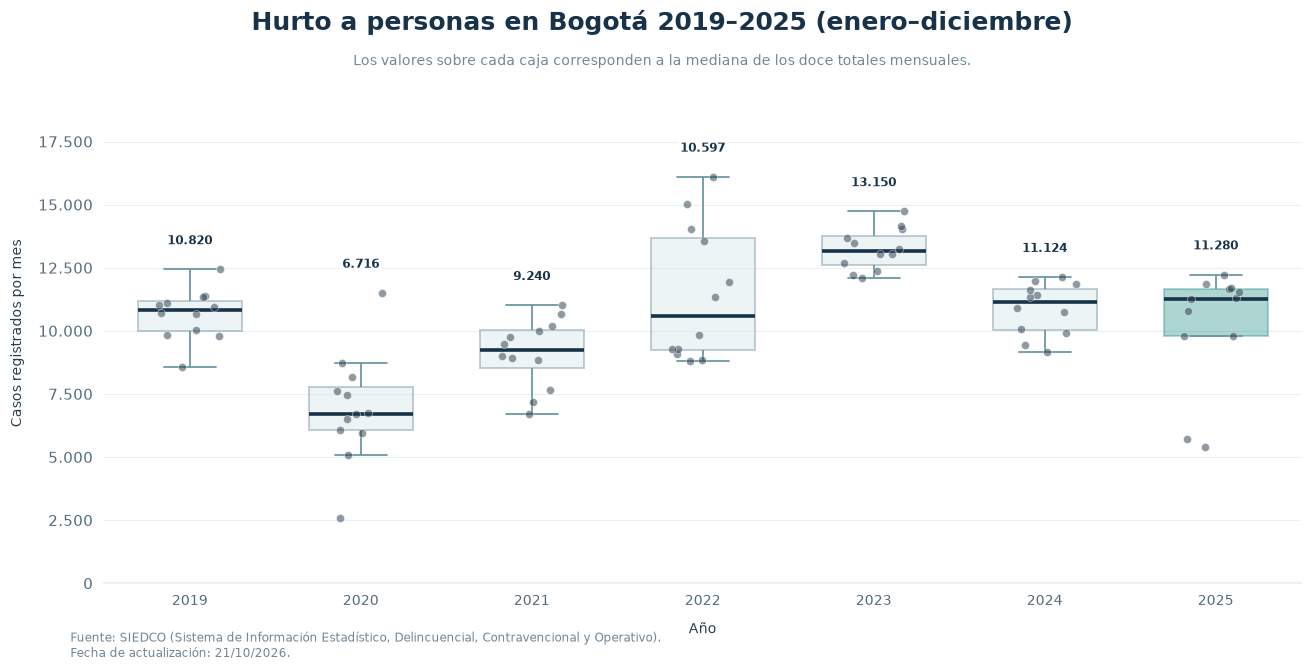

In [4]:
# 5. GRÁFICO 1 — BOXPLOT: doce observaciones mensuales por año.
# Seaborn: boxplot + stripplot. Matplotlib: anotaciones, ejes y exportación.
def dibujar_boxplot(ax, compacto=False):
    sns.boxplot(
        data=mensual, x='Anio', y='Casos', order=ANIOS, ax=ax,
        width=0.61, showfliers=False, whis=1.5,
        color='#CDE2E8', saturation=0.95,
        boxprops={'edgecolor':'#527481', 'linewidth':1.4, 'alpha':0.35},
        medianprops={'color':NAVY, 'linewidth':2.6},
        whiskerprops={'color':'#6694A0','linewidth':1.25},
        capprops={'color':'#6694A0','linewidth':1.25},
    )
    # Destacar la caja más reciente; las doce observaciones siguen visibles.
    if len(ax.patches) >= len(ANIOS):
        ax.patches[len(ANIOS)-1].set_facecolor(BLUE)
        ax.patches[len(ANIOS)-1].set_edgecolor(BLUE)
    # Semilla fija: el desplazamiento horizontal no cambia entre ejecuciones.
    np.random.seed(42)
    sns.stripplot(
        data=mensual, x='Anio', y='Casos', order=ANIOS, ax=ax,
        color='#2C3E50', size=4.3 if compacto else 5.8,
        jitter=0.19, alpha=0.52, zorder=4,
        edgecolor='white', linewidth=0.55,
    )
    medianas = resumen.set_index('Anio')['mediana_mensual']
    for i, anio in enumerate(ANIOS):
        valor = medianas.loc[anio]
        techo = mensual.loc[mensual['Anio'].eq(anio), 'Casos'].max()
        ax.annotate(f'{valor:,.0f}'.replace(',','.'), xy=(i, valor),
                    xytext=(i, techo + mensual['Casos'].max() * 0.055), textcoords='data',
                    ha='center', va='bottom', color=NAVY,
                    fontsize=7.1 if compacto else 8.7, weight='bold',
                    bbox={'facecolor':'white','edgecolor':'none',
                          'alpha':0.88,'pad':1.8}, zorder=6)
    ax.set_xlabel('Año', fontsize=9 if compacto else 10, labelpad=10)
    ax.set_ylabel('Casos registrados por mes', fontsize=9 if compacto else 10, labelpad=10)
    ax.set_xticks(range(len(ANIOS)), [str(a) for a in ANIOS])
    ax.tick_params(axis='x', labelsize=8 if compacto else 10)
    ax.yaxis.set_major_formatter(formato_miles)
    sin_marcos(ax)
    ax.set_axisbelow(True)
    ax.set_ylim(0, mensual['Casos'].max()*1.23)

fig, ax = plt.subplots(figsize=(13.6,7.35))
fig.subplots_adjust(top=0.82, left=0.09, right=0.97, bottom=0.14)
dibujar_boxplot(ax)
textos_figura(fig, 'Hurto a personas en Bogotá 2019–2025 (enero–diciembre)', FUENTE)

fig.text(0.5, 0.86, SUBTITULO_BOXPLOT, ha='center', va='top', fontsize=10, color=MUTED)

guardar(fig, '01_boxplot_medianas_ene_dic_2019_2025')
plt.show()

Guardado: 02_mapa_calor_ene_dic_2019_2025.png


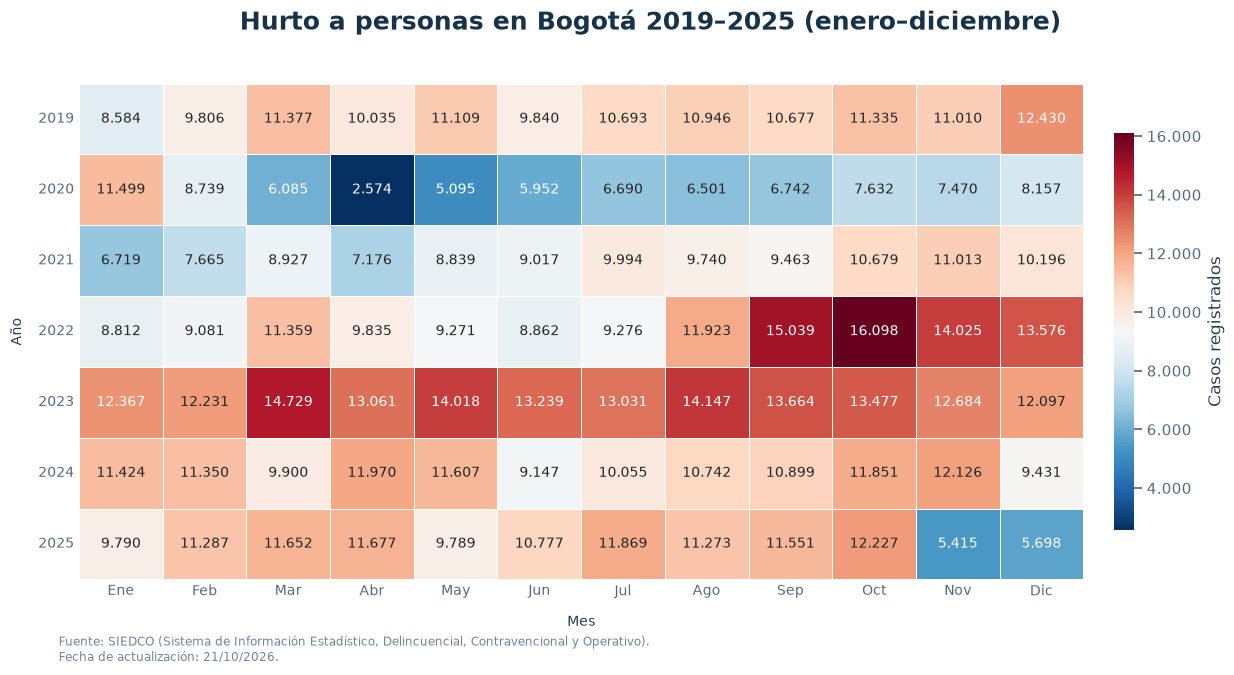

In [5]:
# 6. GRÁFICO 2 — MAPA DE CALOR: comparación año × mes.
# La misma escala de intensidad aplica a todos los años, sin doble eje.
def dibujar_heatmap(ax, compacto=False):
    matriz = (mensual.pivot(index='Anio', columns='Mes_n', values='Casos')
              .reindex(index=ANIOS, columns=range(1,13)))
    if matriz.isna().any().any():
        raise ValueError('Matriz incompleta, no se rellenará con ceros.')
    sns.heatmap(
        matriz, ax=ax, cmap='RdBu_r', vmin=mensual['Casos'].min(), vmax=mensual['Casos'].max(), linewidths=0.5, linecolor='white',
        annot=matriz.apply(lambda col: col.map(lambda v: f'{v:,.0f}'.replace(',', '.'))),
        fmt='', annot_kws={'fontsize':7.2 if compacto else 10.0,
                            'fontweight':'normal'},
        cbar=True, cbar_kws={'label':'Casos registrados', 'shrink':0.8, 'pad':0.025},
        square=False, xticklabels=MESES_C, yticklabels=[str(a) for a in ANIOS],
    )
    barra = ax.collections[0].colorbar
    barra.ax.yaxis.set_major_formatter(formato_miles)
    ax.set_xlabel('Mes', fontsize=9 if compacto else 10, labelpad=12)
    ax.set_ylabel('Año', fontsize=9 if compacto else 10, labelpad=10)
    ax.tick_params(axis='both', length=0, labelrotation=0, labelsize=8 if compacto else 10)
    ax.xaxis.tick_bottom()
    for borde in ax.spines.values(): borde.set_visible(False)

fig, ax = plt.subplots(figsize=(13.6, 7.4))
fig.subplots_adjust(top=0.82, left=0.08, right=0.975, bottom=0.15)
dibujar_heatmap(ax)
textos_figura(fig, 'Hurto a personas en Bogotá 2019–2025 (enero–diciembre)', FUENTE)

guardar(fig, '02_mapa_calor_ene_dic_2019_2025')
plt.show()

Guardado: 03_lineas_2025_vs_2023_2024_ene_dic_2019_2025.png


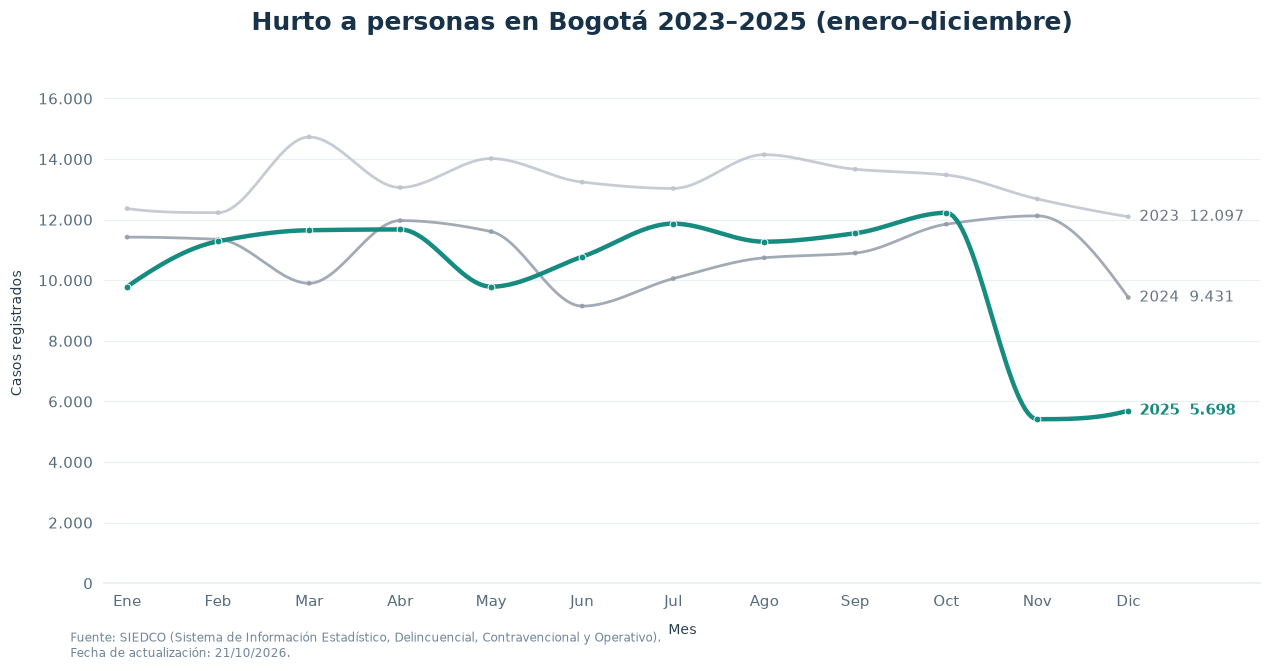

In [6]:
# 7. GRÁFICO 3 — LÍNEAS ESTACIONALES: pocos años de referencia.
# Destacamos 2025; 2023 y 2024 son referencias discretas, no todas las series.
# El eje horizontal representa MESES, no una secuencia histórica continua.
REFERENCIAS = [a for a in [ULTIMO-2, ULTIMO-1] if a in ANIOS]
VISIBLE = REFERENCIAS + [ULTIMO]
COLORES = {ULTIMO-2:'#BCC3CC', ULTIMO-1:'#929CA8', ULTIMO:BLUE}

def dibujar_lineas(ax, compacto=False):
    solo = mensual[mensual['Anio'].isin(VISIBLE)].copy()
    # Curvas PCHIP entre observaciones; puntos y etiquetas muestran datos reales.
    for a in VISIBLE:
        serie = solo.loc[solo['Anio'].eq(a)].sort_values('Mes_n')
        es_actual = (a == ULTIMO)
        # Interpolación que conserva los valores mensuales y la forma local.
        x = serie['Mes_n'].to_numpy()
        y = serie['Casos'].to_numpy()
        x_suave = np.linspace(x.min(), x.max(), 321)
        y_suave = PchipInterpolator(x, y)(x_suave)
        ax.plot(x_suave, y_suave, color=COLORES[a],
                linewidth=3.2 if es_actual else 2.0,
                alpha=1 if es_actual else 0.85,
                zorder=5 if es_actual else 2)
        # Un solo marcador por dato; puntos discretos en todas las series.
        tamano_punto = (18 if compacto else 24) if es_actual else (9 if compacto else 12)
        ax.scatter(x, y, s=tamano_punto,
                   facecolor=COLORES[a], edgecolor='white' if es_actual else 'none',
                   linewidth=0.65 if es_actual else 0,
                   alpha=1 if es_actual else 0.85,
                   zorder=7 if es_actual else 4)
    ax.set_xlim(0.75,13.45)
    ax.set_xticks(range(1,13), MESES_C)
    # Etiquetas junto al dato final: evita leyenda separada y ruido visual.
    for a in VISIBLE:
        val = solo.loc[(solo.Anio.eq(a)) & (solo.Mes_n.eq(12)), 'Casos'].iloc[0]
        ax.annotate(f'{a}  {val:,.0f}'.replace(',', '.'), (12, val), xytext=(8, 0),
                    textcoords='offset points', va='center', ha='left',
                    fontsize=9 if compacto else 11,
                    fontweight='bold' if a == ULTIMO else 'normal',
                    color=BLUE if a == ULTIMO else '#687582')
    ax.set_xlabel('Mes', fontsize=9 if compacto else 10, labelpad=10)
    ax.set_ylabel('Casos registrados', fontsize=9 if compacto else 10, labelpad=10)
    ax.yaxis.set_major_formatter(formato_miles)
    sin_marcos(ax)
    maximo = solo['Casos'].max()
    ax.set_ylim(0, maximo * 1.12)

fig, ax = plt.subplots(figsize=(13.6,7.35))
fig.subplots_adjust(top=0.82, left=0.09, right=0.94, bottom=0.14)
dibujar_lineas(ax)
textos_figura(fig, 'Hurto a personas en Bogotá 2023–2025 (enero–diciembre)', FUENTE)

guardar(fig, '03_lineas_2025_vs_2023_2024_ene_dic_2019_2025')
plt.show()

### Para el documento de justificación que exige la guía

El proyecto incluye exclusivamente **los datos, el notebook reproducible y las figuras**. La guía solicita adicionalmente un **PDF de decisiones de diseño (máximo 2–3 páginas)**, que no se genera aquí porque este paquete se centra en la construcción de visualizaciones.

Para ese PDF, justifica explícitamente: (1) propósito exploratorio y audiencia; (2) por qué el boxplot, el mapa de calor y las líneas representan tres comparaciones complementarias; (3) escalas, unidades, contraste, paleta secuencial en el mapa de calor y énfasis del último año; (4) criterio ético de corte común enero–diciembre y límites de trabajar con conteos absolutos; (5) reproducibilidad de la agregación `sum(Cantidad)` por año–mes.